# Phase 6: Robustness and External Validation (Kaggle version)

Does the model still work when conditions change?

| Part | Question | What we test |
|---|---|---|
| A. Noise | Does it hold up on messier recordings? | Gaussian noise at increasing levels; baseline wander with and without the bandpass filter |
| B. Fewer leads | Could it work on a wearable? | 6 limb leads, leads I + II, lead I only (smartwatch): blanking leads in the 12-lead model vs retraining a CNN on just those leads |
| C. External validation | Does it work at another hospital? | CPSC 2018: 6,877 ECGs from Chinese hospitals, never seen in training |

**Before running (Kaggle settings, right-hand panel):**
1. **Accelerator:** GPU T4 x2 (or GPU P100).
2. **Internet:** On (needs a phone-verified Kaggle account).
3. **Input:** Add Input → search *China Physiological Signal Challenge in 2018* (owner: physionet) → Add.
4. In Step 0, paste the two Google Drive folder links.

Total time about 1–1.5 hours, mostly the retraining in Step 6.

## Step 0: Kaggle Setup — Copy Project Files from Google Drive

In [1]:
# Step 0: Check the GPU, then copy the processed PTB-XL data and trained models from Google Drive (folders shared by link)
import os, tensorflow as tf, keras
print('TensorFlow', tf.__version__, '| Keras', keras.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

DATA_FOLDER_URL = '<paste your Google Drive folder link>'
MODELS_FOLDER_URL = '<paste your Google Drive folder link>'
PROJECT = '/kaggle/working/ecg-project'
os.makedirs(PROJECT, exist_ok=True)

!pip install -q -U gdown
!gdown --folder -q "{DATA_FOLDER_URL}" -O {PROJECT}/data_processed
!gdown --folder -q "{MODELS_FOLDER_URL}" -O {PROJECT}/models
!wget -q -T 60 -t 3 -O {PROJECT}/ptbxl_database.csv https://physionet.org/files/ptb-xl/1.0.3/ptbxl_database.csv
!du -sh {PROJECT}/*

TensorFlow 2.20.0 | Keras 3.13.2 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
1007M	/kaggle/working/ecg-project/data_processed
458M	/kaggle/working/ecg-project/models
6.3M	/kaggle/working/ecg-project/ptbxl_database.csv
360M	/kaggle/working/ecg-project/results


Copies  data_processed` and `models` folders from Google Drive into Kaggle (about 1.2 GB, a few minutes), and fetches the small PTB-XL diagnosis table used for the matched comparison in Step 10. The last line lists what arrived: `data_processed` is about 1 GB and `models` is about 150 MB.

## Step 1: Environment Setup

In [2]:
# Step 1: Locate the copied files, define paths, constants and shared helpers (data loading, CNN builder, filter, metrics)
import sys, glob, time, re, ast, shutil
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from keras import layers
from scipy.signal import butter, filtfilt, resample_poly
from scipy.io import loadmat
from sklearn.metrics import roc_auc_score, roc_curve

def find_dir(name):
    hits = glob.glob(f'{PROJECT}/**/{name}', recursive=True)
    assert hits, f'{name} not found - check the Google Drive download in Step 0'
    return os.path.dirname(hits[0])

OUT, MODEL_DIR = find_dir('X_test.npy'), find_dir('cnn_binary_s0.keras')
RESULTS = f'{PROJECT}/results'
FIGS, PRED_DIR = f'{RESULTS}/figures', f'{RESULTS}/deep_preds'
for d in [FIGS, PRED_DIR]:
    os.makedirs(d, exist_ok=True)
print('Data:', OUT, '| Models:', MODEL_DIR)

LEADS = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
CLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
THR = {'cnn': 0.462, 'resnet': 0.420}                  # thresholds chosen on PTB-XL validation in Phase 3
MU, SD = np.load(f'{OUT}/norm_stats.npy')              # PTB-XL training-set statistics from Phase 1

def load_split(name):
    return np.load(f'{OUT}/X_{name}.npy'), np.load(f'{OUT}/ybin_{name}.npy')

def conv_bn_relu(x, filters, kernel, stride=1):
    x = layers.Conv1D(filters, kernel, strides=stride, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x)

def build_cnn(n_out, input_shape=(1000, 12)):
    """Same CNN architecture as src/models.py (Phase 3)."""
    inp = keras.Input(input_shape)
    x = inp
    for filters in [32, 64, 128, 128, 256]:
        x = conv_bn_relu(x, filters, 7)
        x = layers.MaxPooling1D(2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    return keras.Model(inp, layers.Dense(n_out, activation='sigmoid')(x), name='cnn1d')

def bandpass(x, low=0.5, high=40, fs=100, order=3):
    b, a = butter(order, [low, high], btype='band', fs=fs)
    return filtfilt(b, a, x, axis=1).astype(np.float32)

def ens_predict(ms, X):
    return np.mean([m.predict(X, batch_size=512, verbose=0) for m in ms], axis=0)

def auc_ci(y, p, B=1000, seed=42):
    rng, n, stats = np.random.default_rng(seed), len(y), []
    for _ in range(B):
        i = rng.integers(0, n, n)
        if y[i].min() != y[i].max():
            stats.append(roc_auc_score(y[i], p[i]))
    return roc_auc_score(y, p), *np.percentile(stats, [2.5, 97.5])

def sens_spec(y, p, t):
    return (p[y == 1] >= t).mean(), (p[y == 0] < t).mean()

Data: /kaggle/working/ecg-project/data_processed | Models: /kaggle/working/ecg-project/models


Finds the copied folders wherever Google Drive placed them, and defines the same helpers as the Colab notebooks. The CNN builder is identical to `src/models.py`.

## Step 2: Load Test Data and Models

In [3]:
# Step 2: Load the PTB-XL test set and the 5-seed CNN and ResNet ensembles; confirm the Phase 3 AUROCs
X_test, y_test = load_split('test')
meta = pd.read_csv(f'{OUT}/metadata.csv', index_col='ecg_id')
tm = meta[meta['split'] == 'test'].copy()

load = lambda name: [keras.models.load_model(f'{MODEL_DIR}/{name}_s{s}.keras') for s in range(5)]
M = {'cnn': load('cnn_binary'), 'resnet': load('resnet_binary')}
cnn_multi = load('cnn_multi')

base = {m: ens_predict(M[m], X_test).ravel() for m in M}
for m in M:
    print(f'{m:6s} PTB-XL test AUROC: {roc_auc_score(y_test, base[m]):.3f}')

cnn    PTB-XL test AUROC: 0.943
resnet PTB-XL test AUROC: 0.941


Expect 0.943 (CNN) and 0.941 (ResNet), matching Phase 3. If loading fails with a Keras version error, run `!pip install -q -U keras` in a new cell, then **Run → Restart & clear cell outputs** and run from Step 0 again.

## Part A: Noise Robustness

## Step 3: Gaussian Noise

noise SD 0.00 (SNR   inf dB): CNN 0.943 | ResNet 0.941
noise SD 0.05 (SNR  26.1 dB): CNN 0.943 | ResNet 0.941
noise SD 0.10 (SNR  20.1 dB): CNN 0.943 | ResNet 0.941
noise SD 0.20 (SNR  14.0 dB): CNN 0.943 | ResNet 0.941
noise SD 0.30 (SNR  10.5 dB): CNN 0.941 | ResNet 0.940
noise SD 0.50 (SNR   6.1 dB): CNN 0.938 | ResNet 0.936
noise SD 0.75 (SNR   2.6 dB): CNN 0.932 | ResNet 0.931
noise SD 1.00 (SNR   0.1 dB): CNN 0.920 | ResNet 0.920


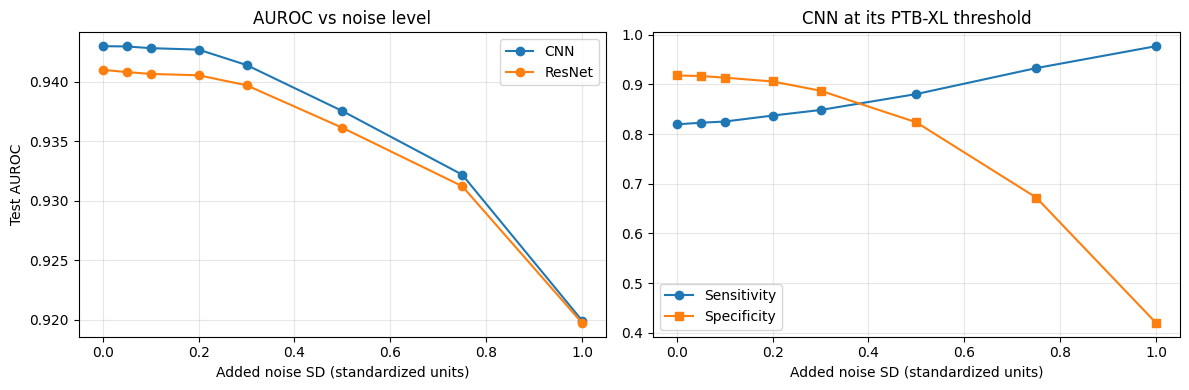

In [4]:
# Step 3: Add white noise at increasing levels, re-apply the pipeline's bandpass filter, and measure AUROC, sensitivity and specificity
rng = np.random.default_rng(42)
sig_power = X_test.var()
rows = []
for sigma in [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]:
    Xn = X_test if sigma == 0 else bandpass(X_test + rng.normal(0, sigma, X_test.shape).astype(np.float32))
    row = {'noise_sd': sigma, 'SNR_dB': np.inf if sigma == 0 else 10 * np.log10(sig_power / sigma ** 2)}
    for m in M:
        p = ens_predict(M[m], Xn).ravel()
        row[f'{m}_AUROC'] = roc_auc_score(y_test, p)
        row[f'{m}_sens'], row[f'{m}_spec'] = sens_spec(y_test, p, THR[m])
    rows.append(row)
    print(f"noise SD {sigma:4.2f} (SNR {row['SNR_dB']:5.1f} dB): CNN {row['cnn_AUROC']:.3f} | ResNet {row['resnet_AUROC']:.3f}")

noise = pd.DataFrame(rows)
noise.to_csv(f'{RESULTS}/robustness_noise.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for m, lab in [('cnn', 'CNN'), ('resnet', 'ResNet')]:
    axes[0].plot(noise.noise_sd, noise[f'{m}_AUROC'], 'o-', label=lab)
axes[0].set(xlabel='Added noise SD (standardized units)', ylabel='Test AUROC', title='AUROC vs noise level')
axes[1].plot(noise.noise_sd, noise.cnn_sens, 'o-', label='Sensitivity')
axes[1].plot(noise.noise_sd, noise.cnn_spec, 's-', label='Specificity')
axes[1].set(xlabel='Added noise SD (standardized units)', title='CNN at its PTB-XL threshold')
for ax in axes: ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{FIGS}/robustness_noise.png', dpi=150); plt.show()

White noise is added on top of each test ECG, then the same 0.5–40 Hz filter from Phase 1 is applied, as it would be in deployment. Noise SD is in standardized units, where 1 equals the typical size of the signal (SNR 0 dB). The right panel shows *how* the CNN fails: losing sensitivity (missed cases) or specificity (false alarms).

## Step 4: Baseline Wander

amplitude 0: raw 0.943 | filtered 0.943
amplitude 0.5: raw 0.941 | filtered 0.943
amplitude 1: raw 0.927 | filtered 0.943
amplitude 2: raw 0.842 | filtered 0.941
amplitude 4: raw 0.692 | filtered 0.927


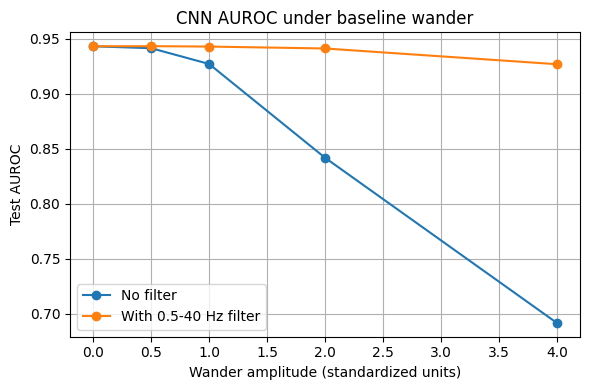

In [5]:
# Step 4: Add slow baseline drift (0.05-0.5 Hz, random phase per lead) and compare the CNN with and without the bandpass filter
t = np.arange(X_test.shape[1]) / 100
rows = []
for amp in [0, 0.5, 1, 2, 4]:
    freq = rng.uniform(0.05, 0.5, (len(X_test), 1, 12))
    phase = rng.uniform(0, 2 * np.pi, (len(X_test), 1, 12))
    Xw = (X_test + amp * np.sin(2 * np.pi * freq * t[None, :, None] + phase)).astype(np.float32)
    for filtered in [False, True]:
        p = ens_predict(M['cnn'], bandpass(Xw) if filtered else Xw).ravel()
        rows.append({'amplitude': amp, 'filtered': filtered, 'AUROC': roc_auc_score(y_test, p)})
    print(f'amplitude {amp}: raw {rows[-2]["AUROC"]:.3f} | filtered {rows[-1]["AUROC"]:.3f}')

wander = pd.DataFrame(rows).pivot(index='amplitude', columns='filtered', values='AUROC')
wander.columns = ['No filter', 'With 0.5-40 Hz filter']
wander.to_csv(f'{RESULTS}/robustness_baseline_wander.csv')
wander.plot(marker='o', figsize=(6, 4), title='CNN AUROC under baseline wander', ylabel='Test AUROC',
            xlabel='Wander amplitude (standardized units)', grid=True)
plt.tight_layout(); plt.savefig(f'{FIGS}/robustness_wander.png', dpi=150); plt.show()

Baseline wander (from breathing or movement) is a slow drift. Comparing the two curves shows whether the Phase 1 bandpass filter protects the model.

## Part B: Fewer Leads

## Step 5: Blanking Leads in the 12-Lead Model

In [6]:
# Step 5: Keep only a subset of leads (others set to zero) and evaluate the existing 12-lead models without retraining
SUBSETS = {'12 leads': list(range(12)), '6 limb leads': list(range(6)), 'Leads I + II': [0, 1],
           'Lead II only': [1], 'Lead I only (smartwatch)': [0]}
rows = []
for name, keep in SUBSETS.items():
    Xs = np.zeros_like(X_test)
    Xs[:, :, keep] = X_test[:, :, keep]
    row = {'leads': name}
    for m in M:
        row[f'{m}_AUROC'] = roc_auc_score(y_test, ens_predict(M[m], Xs).ravel())
    rows.append(row)
    print(f"{name:26s} CNN {row['cnn_AUROC']:.3f} | ResNet {row['resnet_AUROC']:.3f}")
blank = pd.DataFrame(rows).set_index('leads')

12 leads                   CNN 0.943 | ResNet 0.941
6 limb leads               CNN 0.886 | ResNet 0.890
Leads I + II               CNN 0.839 | ResNet 0.812
Lead II only               CNN 0.771 | ResNet 0.719
Lead I only (smartwatch)   CNN 0.682 | ResNet 0.504


The 12-lead models are given ECGs with most leads flattened, showing how a model trained on full ECGs copes with a device that records fewer leads, without retraining.

## Step 6: Retraining a CNN on Fewer Leads

In [7]:
# Step 6: Train the same CNN architecture on lead subsets only (3 seeds each); resumable, saves models and predictions
X_tr, y_tr = load_split('train')
X_va, y_va = load_split('val')

def make_aug(n):
    def aug(x, y):
        x = x * tf.random.uniform([1, n], 0.9, 1.1)
        x = x + tf.random.normal(tf.shape(x), stddev=0.03)
        x = tf.roll(x, tf.random.uniform([], -50, 51, tf.int32), axis=0)
        if n > 1:                                        # never drop the only lead
            x = x * tf.cast(tf.random.uniform([1, n]) > 0.1, x.dtype)
        return x, y
    return aug

def make_ds(X, y, training, seed, n, batch=64):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=seed).map(make_aug(n), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch if training else 256).prefetch(tf.data.AUTOTUNE)

RETRAIN = {'6 limb leads': ('limb6', list(range(6))), 'Leads I + II': ('I_II', [0, 1]),
           'Lead I only (smartwatch)': ('leadI', [0])}

def train_subset(tag, keep, seed, epochs=50, batch=64):
    run = f'cnn_binary_{tag}_s{seed}'
    if os.path.exists(f'{PRED_DIR}/{run}_test.npy'):
        print(f'{run}: already done, skipping'); return
    keras.backend.clear_session()
    keras.utils.set_random_seed(42 + seed)
    n = len(keep)
    model = build_cnn(1, input_shape=(1000, n))
    lr = keras.optimizers.schedules.CosineDecay(1e-3, decay_steps=int(np.ceil(len(X_tr) / batch)) * epochs)
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-2),
                  loss='binary_crossentropy', metrics=[keras.metrics.AUC(name='auc')])
    tr = make_ds(X_tr[:, :, keep], y_tr, True, 42 + seed, n, batch)
    va = make_ds(X_va[:, :, keep], y_va, False, 0, n)
    stop = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=8, restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(tr, validation_data=va, epochs=epochs, callbacks=[stop], verbose=2)
    model.save(f'{MODEL_DIR}/{run}.keras')
    for s, Xs in [('val', X_va), ('test', X_test)]:
        np.save(f'{PRED_DIR}/{run}_{s}.npy', model.predict(Xs[:, :, keep], batch_size=512, verbose=0))
    print(f"{run}: best val AUROC {max(hist.history['val_auc']):.3f} after {len(hist.history['loss'])} epochs "
          f"({(time.time() - t0) / 60:.1f} min)")

for name, (tag, keep) in RETRAIN.items():
    for seed in range(3):
        train_subset(tag, keep, seed)

cnn_binary_limb6_s0: already done, skipping
cnn_binary_limb6_s1: already done, skipping
cnn_binary_limb6_s2: already done, skipping
cnn_binary_I_II_s0: already done, skipping
cnn_binary_I_II_s1: already done, skipping
cnn_binary_I_II_s2: already done, skipping
cnn_binary_leadI_s0: already done, skipping
cnn_binary_leadI_s1: already done, skipping
cnn_binary_leadI_s2: already done, skipping


Trains a new CNN that only ever sees the chosen leads: 6 limb leads (like a 6-lead handheld device), leads I + II, and lead I alone (what a smartwatch records). 3 seeds × 3 lead sets = 9 runs, about 30–45 minutes. Leads I + II are included on purpose: the other four limb leads are calculated from these two, so this model should match the 6-limb-lead one.

## Step 7: Fewer Leads — Results

                   leads                     approach  AUROC    lo    hi  Sensitivity  Specificity
                12 leads               Original model  0.943 0.934 0.952        0.819        0.918
            6 limb leads 12-lead model, leads blanked  0.886   NaN   NaN          NaN          NaN
            6 limb leads     Retrained on these leads  0.919 0.908 0.930        0.819        0.845
            Leads I + II 12-lead model, leads blanked  0.839   NaN   NaN          NaN          NaN
            Leads I + II     Retrained on these leads  0.921 0.910 0.932        0.817        0.877
Lead I only (smartwatch) 12-lead model, leads blanked  0.682   NaN   NaN          NaN          NaN
Lead I only (smartwatch)     Retrained on these leads  0.880 0.866 0.893        0.667        0.932


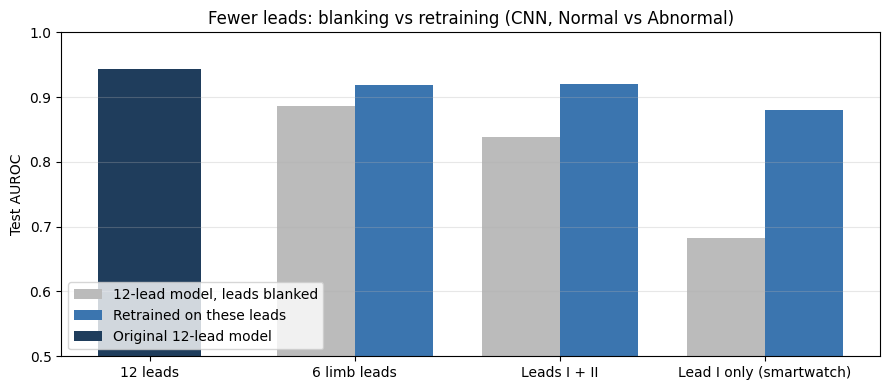

In [8]:
# Step 7: Compare 12-lead, blanked-lead and retrained models: AUROC (95% CI), plus sensitivity/specificity at validation-chosen thresholds
rows = [{'leads': '12 leads', 'approach': 'Original model', **dict(zip(['AUROC', 'lo', 'hi'], auc_ci(y_test, base['cnn']))),
         **dict(zip(['Sensitivity', 'Specificity'], sens_spec(y_test, base['cnn'], THR['cnn'])))}]
for name, (tag, keep) in RETRAIN.items():
    rows.append({'leads': name, 'approach': '12-lead model, leads blanked', 'AUROC': blank.loc[name, 'cnn_AUROC']})
    pv = np.mean([np.load(f'{PRED_DIR}/cnn_binary_{tag}_s{s}_val.npy') for s in range(3)], axis=0).ravel()
    pt = np.mean([np.load(f'{PRED_DIR}/cnn_binary_{tag}_s{s}_test.npy') for s in range(3)], axis=0).ravel()
    fpr, tpr, th = roc_curve(y_va, pv)
    thr = th[np.argmax(tpr - fpr)]
    rows.append({'leads': name, 'approach': 'Retrained on these leads', **dict(zip(['AUROC', 'lo', 'hi'], auc_ci(y_test, pt))),
                 **dict(zip(['Sensitivity', 'Specificity'], sens_spec(y_test, pt, thr)))})

leads_res = pd.DataFrame(rows).round(3)
leads_res.to_csv(f'{RESULTS}/robustness_leads.csv', index=False)
print(leads_res.to_string(index=False))

order = ['12 leads'] + list(RETRAIN)
fig, ax = plt.subplots(figsize=(9, 4))
for k, (appr, col) in enumerate([('12-lead model, leads blanked', '#bbbbbb'), ('Retrained on these leads', '#3b75af')]):
    d = leads_res[leads_res.approach == appr].set_index('leads').reindex(order[1:])
    ax.bar(np.arange(1, len(order)) + (k - 0.5) * 0.38, d.AUROC, 0.38, color=col, label=appr)
ax.bar(0, leads_res.AUROC[0], 0.5, color='#1f3d5c', label='Original 12-lead model')
ax.set(xticks=range(len(order)), xticklabels=order, ylabel='Test AUROC', ylim=(0.5, 1.0),
       title='Fewer leads: blanking vs retraining (CNN, Normal vs Abnormal)')
ax.legend(loc='lower left'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig(f'{FIGS}/robustness_leads.png', dpi=150); plt.show()

The grey vs blue gap shows the gain from training for the device you will actually use; the blue bars vs the 12-lead bar show how much information fewer leads lose.

## Part C: External Validation on CPSC 2018

## Step 8: Locate CPSC 2018 in the Kaggle Input

In [9]:
# Step 8: Find the attached CPSC 2018 files and detect their format (WFDB .hea/.mat headers, or original .mat + REFERENCE.csv)
INPUT = '/kaggle/input'
heas = sorted(h for h in glob.glob(f'{INPUT}/**/*.hea', recursive=True)
              if re.fullmatch(r'A\d{4}\.hea', os.path.basename(h)) and 'extra' not in h.lower())
refs = glob.glob(f'{INPUT}/**/REFERENCE*.csv', recursive=True)

if heas:
    FORMAT = 'wfdb'
    print(f'Found {len(heas)} WFDB records (expected 6,877), e.g. {heas[0]}')
    print(open(heas[0]).read())
elif refs:
    FORMAT = 'original'
    ref = pd.read_csv(refs[0])
    mat_paths = {os.path.basename(p)[:-4]: p for p in glob.glob(f'{INPUT}/**/A*.mat', recursive=True)}
    print(f'Found original CPSC format: {len(ref)} labels in {refs[0]}, {len(mat_paths)} .mat files')
    print(ref.head())
else:
    raise FileNotFoundError('CPSC 2018 not found - add the dataset via "Add Input" (see the top of the notebook)')

Found 6877 WFDB records (expected 6,877), e.g. /kaggle/input/datasets/physionet/china-physiological-signal-challenge-in-2018/Training_WFDB/A0001.hea
A0001 12 500 7500 12-May-2020 12:33:59
A0001.mat 16+24 1000/mV 16 0 28 -1716 0 I
A0001.mat 16+24 1000/mV 16 0 7 2029 0 II
A0001.mat 16+24 1000/mV 16 0 -21 3745 0 III
A0001.mat 16+24 1000/mV 16 0 -17 3680 0 aVR
A0001.mat 16+24 1000/mV 16 0 24 -2664 0 aVL
A0001.mat 16+24 1000/mV 16 0 -7 -1499 0 aVF
A0001.mat 16+24 1000/mV 16 0 -290 390 0 V1
A0001.mat 16+24 1000/mV 16 0 -204 157 0 V2
A0001.mat 16+24 1000/mV 16 0 -96 -2555 0 V3
A0001.mat 16+24 1000/mV 16 0 -112 49 0 V4
A0001.mat 16+24 1000/mV 16 0 -596 -321 0 V5
A0001.mat 16+24 1000/mV 16 0 -16 -3112 0 V6
#Age: 74
#Sex: Male
#Dx: 59118001
#Rx: Unknown
#Hx: Unknown
#Sx: Unknown



Kaggle hosts CPSC 2018, so nothing is downloaded. This cell finds the files and prints one example so the format can be checked. It handles both the PhysioNet layout (`.hea` header + `.mat` signal per record, diagnoses as SNOMED-CT codes) and the original challenge layout (`.mat` files + `REFERENCE.csv` with class numbers 1–9).

## Step 9: Convert CPSC 2018 to the PTB-XL Format and Map Labels

In [10]:
# Step 9: Read each record, reorder leads, take the first 10 s, resample to 100 Hz, filter and standardize with PTB-XL statistics; map labels
CLASS2SNOMED = {1: '426783006', 2: '164889003', 3: '270492004', 4: '164909002', 5: '59118001',
                6: '284470004', 7: '164884008', 8: '429622005', 9: '164931005'}   # original CPSC class numbers

def read_wfdb(hea):
    lines = open(hea).read().splitlines()
    n_sig, fs = int(lines[0].split()[1]), int(lines[0].split()[2])
    sig = [l.split() for l in lines[1:1 + n_sig]]
    names = [s[-1].upper() for s in sig]
    gains = np.array([float(re.match(r'[\d.]+', s[2]).group()) for s in sig])
    info = {}
    for l in lines[1 + n_sig:]:
        if l.startswith('#') and ':' in l:
            k, v = l[1:].split(':', 1)
            info[k.strip()] = v.strip()
    x = loadmat(hea[:-4] + '.mat')['val'].astype(np.float32) / gains[:, None]
    return x.T, fs, names, info

def read_original(rec, labels):
    m = loadmat(mat_paths[rec], squeeze_me=True, struct_as_record=False)['ECG']
    dx = ','.join(CLASS2SNOMED[int(v)] for v in labels if pd.notna(v))
    return np.asarray(m.data, dtype=np.float32).T, 500, [l.upper() for l in LEADS], {'Age': m.age, 'Sex': m.sex, 'Dx': dx}

if FORMAT == 'wfdb':
    items = [(os.path.basename(h)[:-4], lambda h=h: read_wfdb(h)) for h in heas]
else:
    lab_cols = [c for c in ref.columns if 'label' in c.lower()]
    items = [(r.Recording, lambda r=r: read_original(r.Recording, [getattr(r, c) for c in lab_cols]))
             for r in ref.itertuples() if r.Recording in mat_paths]

order, sigs, rows, short = [l.upper() for l in LEADS], [], [], 0
for rec, reader in items:
    x, fs, names, info = reader()
    if len(x) < 10 * fs:
        short += 1; continue
    x = x[:10 * fs, [names.index(l) for l in order]]
    sigs.append(resample_poly(x, 100, fs, axis=0).astype(np.float32))
    rows.append({'record': rec, 'age': info.get('Age'), 'sex': info.get('Sex'), 'dx': str(info.get('Dx', ''))})
Xc_f = bandpass(np.stack(sigs))
cpsc = pd.DataFrame(rows)
print(f'Kept {len(cpsc)} records; skipped {short} shorter than 10 s')

# Unit check: filtered CPSC leads should have a similar spread to PTB-XL (both in millivolts)
ratio = np.median(Xc_f.std(axis=(0, 1)) / SD)
print(f'CPSC / PTB-XL signal spread ratio: {ratio:.2f} (expected roughly 0.5-2)')
if ratio > 100:
    Xc_f /= 1000
    print('Signals looked like microvolts; converted to millivolts.')
Xc = ((Xc_f - MU) / SD).astype(np.float32)
np.save(f'{RESULTS}/cpsc2018_X.npy', Xc); cpsc.to_csv(f'{RESULTS}/cpsc2018_meta.csv', index=False)

cpsc['age'] = pd.to_numeric(cpsc['age'], errors='coerce')
codes = cpsc['dx'].fillna('').str.split(',')
print('Diagnosis codes found:', Counter(c for cs in codes for c in cs).most_common())

NORMAL = {'426783006'}                                                       # sinus rhythm, no other finding
CD = {'270492004': '1AVB', '164909002': 'LBBB', '59118001': 'RBBB'}          # conduction disturbances
STTC = {'429622005': 'STD', '164931005': 'STE'}                              # ST depression / elevation
RHYTHM = {'164889003': 'AF', '284470004': 'PAC', '164884008': 'PVC', '427172004': 'PVC'}
known = NORMAL | set(CD) | set(STTC) | set(RHYTHM)
unknown = Counter(c for cs in codes for c in cs if c not in known)
if unknown:
    print('WARNING - codes outside the mapping (check before trusting results):', unknown)

has = lambda group: codes.apply(lambda cs: any(c in group for c in cs))
cpsc['normal'] = codes.apply(lambda cs: set(cs) == NORMAL)
cpsc['cd'], cpsc['sttc'], cpsc['rhythm'] = has(CD), has(STTC), has(RHYTHM)
cpsc['include'] = cpsc.normal | ((cpsc.cd | cpsc.sttc) & ~cpsc.rhythm)
cpsc['y'] = (~cpsc.normal).astype(int)
for code, lab in {**CD, **STTC}.items():
    cpsc[lab] = codes.apply(lambda cs: code in cs)
print(f"Evaluation set: {cpsc.include.sum()} ECGs ({cpsc.normal.sum()} normal, {(cpsc.include & ~cpsc.normal).sum()} abnormal); "
      f"{(~cpsc.include).sum()} excluded (rhythm-only or rhythm + morphology)")

Kept 6867 records; skipped 10 shorter than 10 s
CPSC / PTB-XL signal spread ratio: 1.16 (expected roughly 0.5-2)
Diagnosis codes found: [('59118001', 1854), ('164889003', 1220), ('426783006', 918), ('429622005', 868), ('270492004', 721), ('164884008', 699), ('284470004', 614), ('164909002', 235), ('164931005', 220)]
Evaluation set: 4349 ECGs (918 normal, 3431 abnormal); 2518 excluded (rhythm-only or rhythm + morphology)


Each CPSC record goes through exactly the PTB-XL pipeline: leads reordered to match, first 10 seconds kept, resampled from 500 to 100 Hz, bandpass-filtered, and standardized with the **PTB-XL** training statistics, as a deployed model would see new data. A unit check confirms the signals are on the same scale as PTB-XL.

**Label mapping** (CPSC uses SNOMED-CT codes for 9 classes; our "abnormal" label covers diagnostic statements, not rhythm):

| CPSC class | Code | Used as |
|---|---|---|
| Normal sinus rhythm | 426783006 | Normal (only if it is the sole code) |
| 1st-degree AV block, LBBB, RBBB | 270492004, 164909002, 59118001 | Abnormal (conduction disturbance) |
| ST depression, ST elevation | 429622005, 164931005 | Abnormal (ST/T change) |
| AF, PAC, PVC | 164889003, 284470004, 164884008 | Excluded: rhythm diagnoses our labels do not cover |

## Step 10: External Validation Results

 model                          dataset    n  abnormal  AUROC    lo    hi  Sensitivity  Specificity  best_threshold_here
   CNN PTB-XL test (matched conditions) 1059       201  0.978 0.966 0.987        0.900        0.927                0.628
   CNN             CPSC 2018 (external) 4349      3431  0.920 0.911 0.928        0.760        0.891                0.230
ResNet PTB-XL test (matched conditions) 1059       201  0.977 0.964 0.987        0.945        0.903                0.696
ResNet             CPSC 2018 (external) 4349      3431  0.920 0.911 0.928        0.783        0.873                0.204

Detection rate per condition (CNN, PTB-XL threshold):
           condition  CPSC n  CPSC detected  PTB-XL n  PTB-XL detected
                1AVB     713          0.743      61.0            0.836
                LBBB     190          0.995      42.0            1.000
                RBBB    1576          0.932      37.0            1.000
                 STD     811          0.481      69.0   

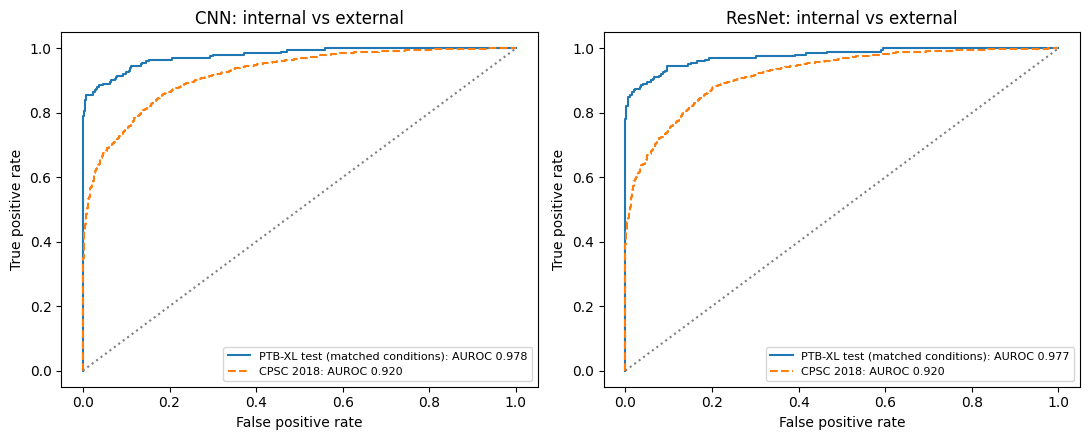

In [11]:
# Step 10: AUROC with 95% CIs on CPSC vs a matched PTB-XL subset, sensitivity/specificity at PTB-XL thresholds, and per-condition detection
ev = cpsc[cpsc.include].reset_index(drop=True)
Xe = Xc[cpsc.index[cpsc.include].values]
ye = ev.y.values
p_ext = {m: ens_predict(M[m], Xe).ravel() for m in M}
pm_ext = ens_predict(cnn_multi, Xe)

# Matched PTB-XL comparison: pure normal ECGs vs ECGs with the same conditions, no rhythm codes
PTB_MATCH = {'1AVB': '1AVB', 'CLBBB': 'LBBB', 'CRBBB': 'RBBB', 'STD_': 'STD', 'STE_': 'STE'}
PTB_RHYTHM = {'AFIB', 'AFLT', 'PAC', 'PVC', 'SVARR', 'BIGU', 'TRIGU', 'SVTAC', 'PSVT'}
db_path = f'{PROJECT}/ptbxl_database.csv'
if os.path.exists(db_path) and os.path.getsize(db_path) > 1e6:
    db = pd.read_csv(db_path, index_col='ecg_id')
    scp_t = db.loc[tm.index, 'scp_codes'].apply(ast.literal_eval)
    no_rhythm = ~scp_t.apply(lambda d: any(c in PTB_RHYTHM for c in d))
    ptb_norm = ((tm.superclass == 'NORM') & no_rhythm).values
    ptb_abn = (scp_t.apply(lambda d: any(c in PTB_MATCH for c in d)) & no_rhythm).values
    sel, ptb_label = ptb_norm | ptb_abn, 'PTB-XL test (matched conditions)'
    y_ptb = ptb_abn[sel].astype(int)
else:
    print('ptbxl_database.csv unavailable - comparing against the full PTB-XL test set instead')
    scp_t = None
    sel, ptb_label, y_ptb = np.ones(len(tm), bool), 'PTB-XL test (all)', y_test.astype(int)

rows = []
for m, lab in [('cnn', 'CNN'), ('resnet', 'ResNet')]:
    for dset, y, p in [(ptb_label, y_ptb, base[m][sel]), ('CPSC 2018 (external)', ye, p_ext[m])]:
        auc, lo, hi = auc_ci(y, p)
        se, sp = sens_spec(y, p, THR[m])
        fpr, tpr, th = roc_curve(y, p)
        rows.append({'model': lab, 'dataset': dset, 'n': len(y), 'abnormal': int(y.sum()), 'AUROC': auc, 'lo': lo, 'hi': hi,
                     'Sensitivity': se, 'Specificity': sp, 'best_threshold_here': th[np.argmax(tpr - fpr)]})
ext = pd.DataFrame(rows).round(3)
ext.to_csv(f'{RESULTS}/external_validation.csv', index=False)
print(ext.to_string(index=False))

print('\nDetection rate per condition (CNN, PTB-XL threshold):')
det = []
for ptb_code, lab in PTB_MATCH.items():
    row = {'condition': lab, 'CPSC n': ev[lab].sum(), 'CPSC detected': (p_ext['cnn'][ev[lab].values] >= THR['cnn']).mean()}
    if scp_t is not None:
        ptb_has = scp_t.apply(lambda d: ptb_code in d).values & no_rhythm.values
        row.update({'PTB-XL n': ptb_has.sum(), 'PTB-XL detected': (base['cnn'][ptb_has] >= THR['cnn']).mean()})
    det.append(row)
det.append({'condition': 'Normal (specificity)', 'CPSC n': ev.normal.sum(),
            'CPSC detected': (p_ext['cnn'][ev.normal.values] < THR['cnn']).mean()})
det = pd.DataFrame(det).round(3)
det.to_csv(f'{RESULTS}/external_detection_by_condition.csv', index=False)
print(det.to_string(index=False))

print('\nTask B outputs on CPSC (CNN ensemble), each condition group vs normal ECGs:')
for name, k, grp in [('CD output: 1AVB/LBBB/RBBB', CLASSES.index('CD'), ev.cd.values),
                     ('STTC output: ST depression/elevation', CLASSES.index('STTC'), ev.sttc.values)]:
    s = grp | ev.normal.values
    print(f'  {name:38s} AUROC {roc_auc_score(grp[s].astype(int), pm_ext[s, k]):.3f} (n = {s.sum()})')

print('\nCPSC by age (CNN):')
for g, s in [('Under 40', (ev.age < 40).values), ('40 and over', (ev.age >= 40).values)]:
    if s.sum() and ye[s].min() != ye[s].max():
        print(f'  {g:12s} n = {s.sum():5d} | AUROC {roc_auc_score(ye[s], p_ext["cnn"][s]):.3f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (m, lab) in zip(axes, [('cnn', 'CNN'), ('resnet', 'ResNet')]):
    for dset, y, p, ls in [(ptb_label, y_ptb, base[m][sel], '-'), ('CPSC 2018', ye, p_ext[m], '--')]:
        fpr, tpr, _ = roc_curve(y, p)
        ax.plot(fpr, tpr, ls, label=f'{dset}: AUROC {roc_auc_score(y, p):.3f}')
    ax.plot([0, 1], [0, 1], ':', c='grey')
    ax.set(xlabel='False positive rate', ylabel='True positive rate', title=f'{lab}: internal vs external')
    ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIGS}/external_roc.png', dpi=150); plt.show()

- **Internal vs external AUROC.** CPSC is compared against a *matched* PTB-XL subset with the same conditions (1st-degree AV block, LBBB, RBBB, ST depression, ST elevation vs normal). The gap between them is the generalization gap.
- **Threshold transfer.** Sensitivity and specificity use the PTB-XL thresholds unchanged; `best_threshold_here` shows where the optimal cut-off would sit on each dataset.
- **Per-condition detection, Task B outputs and age** show which conditions transfer well, and whether the under-40 weakness appears at another hospital too.

## Step 11: Phase 6 Summary

In [12]:
# Step 11: One table with the headline robustness numbers for the CNN
pick = lambda q: leads_res.query(q).AUROC.item()
summary = pd.DataFrame([
    {'test': 'PTB-XL test, 12 leads (reference)', 'AUROC': roc_auc_score(y_test, base['cnn'])},
    {'test': 'Moderate noise (SD 0.3)', 'AUROC': noise.loc[noise.noise_sd == 0.3, 'cnn_AUROC'].item()},
    {'test': 'Heavy noise (SD 1.0, SNR ~0 dB)', 'AUROC': noise.loc[noise.noise_sd == 1.0, 'cnn_AUROC'].item()},
    {'test': 'Strong baseline wander, filtered (amp 4)', 'AUROC': wander.loc[4, 'With 0.5-40 Hz filter']},
    {'test': '6 limb leads, retrained', 'AUROC': pick("leads == '6 limb leads' and approach == 'Retrained on these leads'")},
    {'test': 'Lead I only, retrained', 'AUROC': pick("leads == 'Lead I only (smartwatch)' and approach == 'Retrained on these leads'")},
    {'test': ptb_label, 'AUROC': ext[(ext.model == 'CNN') & ext.dataset.str.startswith('PTB')].AUROC.item()},
    {'test': 'CPSC 2018 external', 'AUROC': ext[(ext.model == 'CNN') & ext.dataset.str.startswith('CPSC')].AUROC.item()},
]).round(3)
summary.to_csv(f'{RESULTS}/robustness_summary.csv', index=False)
print(summary.to_string(index=False))

                                    test  AUROC
       PTB-XL test, 12 leads (reference)  0.943
                 Moderate noise (SD 0.3)  0.941
         Heavy noise (SD 1.0, SNR ~0 dB)  0.920
Strong baseline wander, filtered (amp 4)  0.927
                 6 limb leads, retrained  0.919
                  Lead I only, retrained  0.880
        PTB-XL test (matched conditions)  0.978
                      CPSC 2018 external  0.920


A single table of the headline CNN numbers for the write-up and README.

## Step 12: Package Results for Download

In [13]:
# Step 12: Zip all Phase 6 results (CSVs, figures, predictions) for download; also copy the retrained lead-subset models
for f in glob.glob(f'{MODEL_DIR}/cnn_binary_*_s*.keras'):
    if any(tag in f for tag in ['limb6', 'I_II', 'leadI']):
        os.makedirs(f'{RESULTS}/models_reduced_leads', exist_ok=True)
        shutil.copy(f, f'{RESULTS}/models_reduced_leads/')
shutil.make_archive('/kaggle/working/phase6_results', 'zip', RESULTS)
print('Download /kaggle/working/phase6_results.zip from the Output panel (right side) and upload it to Google Drive > ecg-project')

Download /kaggle/working/phase6_results.zip from the Output panel (right side) and upload it to Google Drive > ecg-project


Kaggle's files disappear when the session ends, so download `phase6_results.zip` (right-hand panel → Output → `/kaggle/working`) and unzip it into `ecg-project/results` on Google Drive. Then download this notebook too (File → Download notebook) and send it to me.